# **ЛА_COLAB_02: занурення до лінійної алгебри**

**Петрик Андрій МФ-22**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx
import pandas as pd
from scipy import linalg
import sympy

## Задача 4: лінійні простори

Оберіть і розв'яжіть одну із задач 4.1 або 4.2 на ваш вибір. Іншу задачу видаліть з шаблону.

🧩 **4.2. Шифр Хілла.**

 У цій задачі ми познайомимося з шифром Хілла(Гілла) -- одним з методів шифрування інформації, і проведемо його лінійноалгебраїчний аналіз. Американський математик Лестер Хілл винайшов його 1929 року, і, хоча шифр виявився не дуже вдалим (далі ми поговоримо, з яких причин), він став важливою сходинкою в розвитку криптографії, оскільки продемонстрував, наскільки продуктивним може бути саме математичний підхід до цієї науки.

Для побудови шифру спочатку обирають алфавіт символів, з яких можуть складатися повідомлення, що їх треба шифрувати. Можна взяти деякий стандартний алфавіт, наприклад, латинський, в якому 26 літер, але зручніше використовувати алфавіт, кількість символів у якому є простим числом. Тому ми додамо до латинського алфавіту ще три символи:  '$\quad $'(пробіл), '.'(крапка), ','(кома) й використовуватимемо алфавіт з 29 символів. Символам алфавіту взаємно однозначно відповідають елементи поля $\mathbb{Z}_{29}$, що є класами лишків за модулем 29, але ми позначаємо їх як числа: A -- 0, B -- 1, C -- 2, ... , Z -- 25, '$\ $' -- 26, '.' -- 27, ',' -- 28.

Учасників обміну повідомленнями в криптографії зазвичай називають Алісою та Бобом. Шифрування повідомлень здійснюється за допомогою ключа, яким володіють Аліса та Боб та тримають його в секреті. Шифр Хілла передбачає, що ключем є квадратна матриця (деякого порядку $n$), елементи якої беруться з поля $\mathbb{Z}_{29}$ (саме для того, щоб класи лишків утворили поле, ми й обрали 29 символів). Для того, щоб зашифрувати повідомлення й надіслати його Бобу, Аліса

1. Розбиває повідомлення на блоки довжини $n$.
2. Переводить символи цих блоків у елементи поля $\mathbb{Z}_{29}$, отримуючи таким чином набір векторів довжини $n$: $u_1, \dots, u_s$.
3. Множить матрицю-ключ $K$ на кожен з векторів, отримуючи набір зашифрованих векторів: $Ku_1, \dots, Ku_s$.
4. Надсилає цей набір Бобу.

Щоб дешифрувати повідомлення (тобто зрозуміти, яким був вихідний текст), Бобу достатньо помножити кожен з векторів, що він їх отримав, на матрицю, обернену до матриці ключа: $K^{-1}$. Зокрема, обираючи матрицю-ключ, треба подбати про те, щоб вона була обертовною, тобто невиродженою над полем $\mathbb{Z}_{29}$.


1️⃣ Реалізуйте алгоритми, що здійснюють шифрування та дешифрування Хілла.
Передбачте допоміжні функції:

1. Функцію розбиття тексту на блоки певної довжини (якщо якийсь з блоків виявиться коротшим, то можна доповнити його деякою послідовністю символів).
2. Функції переведення текстових блоків у вектори з елементів поля $\mathbb{Z}_{29}$ (і навпаки).
3. Функцію перевірки того, що матриця-ключ є обертовною та знаходження оберненої матриці до матриці-ключа.

Протестуйте ваші функції та продемонструйте їхню роботу.

In [ ]:
class Mode29: #creating all operations available in the field of mod 29
    Mod = 29

    def __init__(self, value): #use it for creating and initializating an instance of the class: sth. like a constructor in Java
        self.value = value % Mode29.Mod
    
    def __add__(self, other: "Mode29") -> "Mode29": # явно вказуємо тип 2-ї змінної та повернення
        return Mode29((self.value + other.value) % Mode29.Mod)# кастуємо до потрібного типу даних результат
    
    def __sub__(self, other: "Mode29") -> "Mode29":
        return Mode29((self.value - other.value) % Mode29.Mod)
    
    def __mul__(self, other: "Mode29") -> "Mode29":
        return Mode29((self.value * other.value) % Mode29.Mod)
    
    #one for comparing one with another:
    def __eq__(self, other: "Mode29") -> bool:
            if not (isinstance(other, Mode29)): #cheching if it's an instance of the class
                return NotImplemented
            return self.value == other.value
    
    def __repr__(self):
        return f"({self.value}) mod 29"
    
class Hill:
    def __init__(self):
        
        message = input("Please enter the message you want to encrypte: ").upper()
        self.message = message
        
        n = int(input("Please enter the number of elements that will be processed at a time"))
        self.n = n
        
        data = list(map(int, input("Please enter the key for your cipher: ").split())) # input().split() - separetes each token, creating an list of strings, then we're applying map() that converts input().split() into an list of int, afterwards we're creating a list of it
        key = np.array(data).reshape(self.n, self.n) # transforming the matrix we've created into n * n one
        if(np.gcd(int(round(np.linalg.det(key))),  29) != 1):
            print("Pleace check if you've entered the key correctly! ")
            raise ValueError("Invalid key matrix: gcd(det(key), 29) != 1") 
        self.key = key
        
    def split_message(self):
        chunks = [] #creating a list for processing a message
        mes_len = len(self.message)
        for i in range(0, mes_len, self.n): #we're going from 0 through mes_len using self.n steps between iterations
            chunk = self.message[i:i + self.n] # begin with the range [0, n], then [n+1, 2n], ..., [n-(n-1), n^n]
            chunks.append(chunk)
        for i in range(len(chunks)): #going though every chunk and acheck if it's filled
            if(len(chunks[i]) < self.n): #if its length is less, adding spaces:
               missing = self.n - len(chunks[i]) #calculating how many spaces should be added
               missing = ' ' * missing #creating a string variable
               chunks[i] = chunks[i] + missing # assign the merged string to the old chunk
        self.chunks = chunks #saving an array of chunks in the class
    
    #create a dictionary for conversion letters into numbers:
    alphabet = {
        
       'A': 0,  'B': 1,  'C': 2,  'D': 3,  'E': 4,
       'F': 5,  'G': 6,  'H': 7,  'I': 8,  'J': 9,
       'K': 10, 'L': 11, 'M': 12, 'N': 13, 'O': 14,
       'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19,
      'U': 20, 'V': 21, 'W': 22, 'X': 23, 'Y': 24,
       'Z': 25, ' ': 26, '.': 27, ',': 28
    }

    # inverse_aphabet = {} #creating a dictionary
    # for key in alphabet:
    #     value = alphabet[key] #obtsining the value of each key
    #     inverse_aphabet[value] = key #passing the value as a key and inserting key as a value
    inverse_alphabet = {value: key for key, value in alphabet.items()} # dict_name.item returns an object containing 2 variables: the key and its value
    
    def message_to_matrix(self):
        self.split_message() #to have self.chunks

        matrix = [] 
        for chunk in self.chunks:
            row = list(map(self.alphabet.__getitem__, chunk)) #__getitem__() returns a value of some key of a dictionary
            matrix.append(row) #append also works with 2-dim lists(adding a list to the last element of a list)
        matrix = np.array(matrix) #converting a matrix as a list of lists into Numpy's one
        self.message_to_numbers = matrix
    
    def encrypting(self):
        self.message_to_matrix()
        self.ciphered_message = (
            self.key @ self.message_to_numbers.T #transpose a matrix so that a column rather than a row represents a chunk, then % 29 since we're working in the field of Z_29
            ) % 29 

    def print_enctypted_message(self):
        ciphered_message_string = []
        for block in self.ciphered_message:
            for number in block: 
                   ciphered_message_string.append(str(number))
        ciphered_message_string = ' '.join(ciphered_message_string)
        print(ciphered_message_string)
    
    def algebraic_complements(self): #C^T, where C - a matrix of algebraic complements(c_(ij) = (-1)^(i + j) * M_{ij}, where Mij = a minor - a determinant of a key without i-th row and j-th column)
        cofactor_matrix = np.zeros((self.n, self.n), dtype=int)
        for i in range(self.n):
            for j in range(self.n):
                sign = (-1)**(i + j)
                minor = np.delete(self.key, i, axis = 0) # returns a matrix without the i-th row, axis = 0 means to work on the matrix's rows(one-dimensional operation)
                minor = np.delete(minor, j, axis = 1) # axis = 1 means we're working with columns: deleting the j-th column
                minor_det = int(round(np.linalg.det(minor))) #calculating a determinant, rounding the result because np.linalg.det returns a float value
                cofactor_matrix[i][j] = (sign *  minor_det) % 29
        self.cofactor_matrix = cofactor_matrix.T
             
    def calculate_decrypting_key(self):
        self.algebraic_complements()
        # since det(key) != 0 -> key^(-1) = either A|E, where E - an id-,atrix or 1/det(key) * C^T

        # A = key -> A^(-1) = (det A)^(-1) * C^T mod 29
        # self.decrypting_key = ( #since we're working in the finite field of 29, we can't just have a value that is the result of division 1 by det(A) because the result doesn't belong to Z_29
        #     (1/np.linalg.det(self.key)) * self.cofactor_matrix
        #     ) % 29

        #since we're in Z_29, we need to perform the division(a/b) as a/b = x <=> ax = b mod 29 
        #afterwards, we'd solve this eq. with Evklid: b = ax - k*29, k belongs Z
        #but there's pow() in Py: pow(base, exponent, modulo)b -> pow(8, -1, 29) <=> 1/8 = x mod 29 <=> 8x = 1 mod 29 -> 8x - 29k = 1 mod 29 etc
        det_key = int(round(np.linalg.det(self.key)))
        inverse_det  = pow(det_key, -1, 29) #(det(A))^(-1)
        self.decrypting_key = (inverse_det * self.cofactor_matrix) % 29 # A^(-1) = det(A)^(-1) * adj(A) mod 29

    def decryption_message(self):
        decrypted_message = []
        self.calculate_decrypting_key()
        for column in self.ciphered_message.T: #since NumPy iterates over rows, we're transposng the matrix to work with the columns
            column = (self.decrypting_key @ column) % 29 #decrypting the column: now, the column's value have the elements that can be mapped with the keys of the inverse alphabet; afterwards we are getting the modulus of the multiplicationresult in case the matrix's elements are bigger than the elementf of Z_29
            decrypted_message.append(list(map(self.inverse_alphabet.__getitem__, column)))
        self.decrypted_message = decrypted_message

    def decrypted_to_string(self):
        self.decryption_message()
        #what do we have? a list of lists, in each list there're a character: 
        #What we need to do? to merge this characters into one sequence
        decrypted_message_string = []
        for block in self.decrypted_message:
            for char in block:
                decrypted_message_string.append(char)
        decrypted_message_string = ''.join(decrypted_message_string)
        return decrypted_message_string

            
print("Program started: ")
a = Hill() 
a.encrypting()
a.print_enctypted_message()  
print(a.decrypted_to_string())    

Далі ми поговоримо про те, чи є шифр Хілла стійким до зламу. Тобто, якщо ворог (якого в криптографії зазвичай називають Євою) перехопить зашифроване повідомлення, то наскільки легко йому буде розшифрувати повідомлення, не володіючи попередньо секретним ключем.

2️⃣ Нехай Єва знає розмір матриці-ключа $n$ і намагається розшифрувати повідомлення, зробивши повний перебір усіх можливих матриць. Пригадаємо, що матриця-ключ є невиродженою над полем $\mathbb{Z}_{29}$, тобто її рядки є лінійно незалежними векторами у просторі $\mathbb{Z}_{29}^n$. Зясуйте, скільки матриць має перебрати Єва. Зробіть висновки, чи є метод ``грубої сили'' придатним до зламу шифра Хілла.

If Eva knows the size of the key, which is equal to $n$, it gets easier for her to find the entire key-matrix, altough without knowing what kind of a vector space($\mathbb{Z}_{p}^n$, where p - a prime number, n - ) the key belongs to it won't be that easier. 


 - What she knows: 
   - The dimension of the key
- What else she needs to find out:
  - The finite field the key's elements belongs to($\mathbb{Z}_{p}^n$)

If we're using $p = 29$, then we have $29^n$ vectors in $\mathbb{Z}_{29}^n$ and $n$ linarly independent vectors.

 Then, in order to choose the very first vector of the key, we have $29^n -1$ ways, since $0_{\mathbb{Z}_{29}^n}$ can't be there. After this,  we have $29^n  - 29$ ways left to chose the second vector, as follows we choose all vectors left: $29^n - 29n$, i.e.: $$N = \prod_{k = 1}^{n - 1}(29^n  - 29^k) $$

Hence, Eva would have to go through $N$ matrix in the worst case to find the key.

For example, assuming $n = 2$ $\implies$ $|\forall \vec{v} \in \mathbb{Z}_{29}^2| = 29 \cdot 29 = 841$.

1. To chose the very first column of the key, we have $29^2 - 1 = 840$ ways, since $\vec{0_{Z_{29}^2}}$ can't be "independent". 
2. For the second one, there're $29^2- 29 = 812$ ways left.

Since we're performin this all in $\mathbb{Z}_{29}^2$, the maximum number of linearly independnt vectors is $2$ that's why the number to choose elements of the key is equal to:
 $$(29^2 - 1)\cdot (29^2 - 29) = 682,080$$

**Conclusion:** The Hill cipher can't be reliable because it's not that difficult for a computer to go through this number of combinations, which performs from a milion to one bilion of operations per second. Even writing the program to through those matrices won't be that hard.

3️⃣ Нехай тепер для зламу шифру Єва спробує використати метод частотного аналізу. Метод ґрунтується на тому, що в текстах різні символи зустрічаються з різними частотами. Наприклад, в україномовних текстах найчастіше вживається літера 'о', а в англомовних -- літери 't', 'e'. Обчислюючи частоти, з якими в зашифрованому тексті зустрічається той чи інший символ, можна висловити припущення, якому символу він відповідає у вихідному тексті. Приклад використання частотного аналізу можна зустріти в оповіданнях "Танцюючі чоловічки" Артура Конан Дойля і "Золотий жук" Едгара Алана По. А у реальному житті цим методом користувався, наприклад, французький історик Жан-Франсуа Шампольйон, розшифровуючи єгипетські ієрогліфи.

Поміркуйте над тим, чи варто Єві скористатися частотним аналізом, розшифровуючи шифр Хілла?

Так як частатний аналіз вимагає роботи з окремими елментами, тобто з шифруванням окремого символа, частоту якого ми знємо, то через те, що шифрування Хілла шифрує не окремий символ, а блоки інформації, які потім модифікуються ключом, однакові символи перед шифруванням будуть представлені різними символами з алфавіту після шифрування. Саме тому ми не зможемо визначити патерн ОКРЕМИХ символів(різні символи представлятимуть один і той самий елемент)

Чому вони не повторюються? Тому що ми множимо БЛОК символів на матрицю-ключ. Хоча, якщо в деяких блоках будуть міститись однакові слова, наприклад в укр.мові: тому що, але і т.д., то в усіх цих блоках вони будуть однаковими через однаковий ключ.

 4️ Ще один підхід до зламу шифра Хілла передбачає перехоплення достатньо великої кількості повідомлень і застосування методу "відомого відкритого тексту". Метод полягає в тому, що часто можна зробити припущення про те, яка інформація точно має міститися в повідомленні. Наприклад, повідомлення зазвичай починається зі звернення "Привіт, Боб!", "Юстас Алексу" та таке інше. В оповіданні "Танцюючі чоловічки" Шерлок Холмс (Голмс) використав також і цей метод, припустивши, що повідомлення починаються з імені героїні.

 Якщо Єва знає, що має розшифрувати матрицю певного розміру $n$, то вона може вважати елементи цієї матриці невідомими. Далі, Єва має скласти систему умов вигляду $v=Ku$, де  $v$ -- фрагменти перехоплених повідомлень, а $u$ -- фрагменти вихідних повідомлень, про які Єва здогадується, чому вони дорівнюють (тобто $u, v$ вважаються відомими).

Поясніть, яким чином Єва зможе знайти матрицю $K$ з цих умов. Також поміркуйте над тим, скільки умов вигляду $v=Ku$ має скласти Єва, щоб це здійснити.


1. Якщо відомі частина вхідного і вихідного повідомлення, що менші  $n$, то ми можемо зменшити к-сть матриць-ключів, від максимальної - $\prod_{k = 0}^{n-1}(29^n - 29^k)$ до афінного підпростору матриць($\mathcal{M}$) потужністю $29^{n(n - m)}$, де $m$ - к-сть відомих елементів матриці: $rank(U)$.
Вектори $u, v$ - відомі, то $Ku \to \begin{pmatrix} a & b & c \\ d & e & f \\ g & h & i \end{pmatrix} \begin{pmatrix} u_1 \\ u_2 \\ u_3 \end{pmatrix} = \begin{pmatrix} v_1 \\ v_2 \\ v_3 \end{pmatrix} \to \begin{pmatrix} au_1 + bu_2 + cu_3 \\ du_1 + eu_2 + fu_3 \\ gu_1 + hu_2 + iu_3 \end{pmatrix} = \begin{pmatrix} v_1 \\ v_2 \\ v_3 \end{pmatrix}$ далі просто вираємо залежні змінні через незалежні, таким чином ми зменшимо к-сть невідомих змінних до $m$, що є к-сть незалежних змінних.


2. Якщо ж к-сть елементів $u, v \geq n$, то ми можемо побудувати матриці: $V_{n \times n}, U_{n \times n}$, за допомогою яких, за умови, що $\det(U) \neq 0$,  ключ знаходиться однозначно. Тобто маємо: $A \cdot U = V \implies A = V \cdot U^{-1}$, де $U^{-1}$ - обернена матриця. (Все так само, як у $\mathbb{R}$: $u \cdot x = v$, де $u,v,x \in \mathbb{R} \implies x = v \cdot u^{-1}$). 

Тобто маючи частинку вхідного та вихідного тексту, розмір якої хоча б $n$, матриця вхідного ключа є оборотною: $\det(U) \neq 0$, ключ знаходиться однозначно. 





5️⃣ Зробіть загальний висновок, до яких способів зламу не є стійким шифр Хілла. Знайдіть інформацію (або придумайте самі) про те, як можна змінити шифр Хілла, щоб ускладнити його злам. Не забудьте вказати джерела.

Якщо ми маємо лише зашифроване повідомлення і  не знаємо розмірності ключа, то шифр можна вважати "безпечним". Але, якщо відома хоча б розмірність ключа, чи хоча б частинка вихідного, зашифрованого, повідомлення, то максимальна кількість матриць-ключів, які потрібно перебрати, щоб знайти правильний, зменшується в рази(описано в минулому завданні)

Головною проблемою шифра Хілла є його лінійність:

 **тому що порпри те**, 
 > що можна було б мати додаткові секретні матриці проінексовані від 0 до 29,  які б множились на початковий ключ, при 
 > цьому вибір додаткового ключа визначався б від того, який блок зараз модифікується: $M_{j} = j$ mod 29, де $j$ - порядок > блока, тобто, якщо блок є 31-м, тоді ми множимо початковий ключ на $31$ mod $29 = 2$-гу матрицю $\quad$ 
 
 **ми все ще зможемо відновити ключ через лінінйність.**

 Тому рішенням було б використання декількох перетворень: лініних та нелінійних, наприклад: $P \xrightarrow{S_{1}} P_{S_{1}} \xrightarrow{\mathcal{L}} P_{\mathcal{L}(S_{1})} \xrightarrow{S_{2}} P_{S_{2}(\mathcal{L}(S_{1}))}$, де $S_{1}, S_{2}$ - нелінійні перетворення, $\mathcal{L}$ - лінінйне перетворення, наприклад. наша ключ-матриця в завданні.

<font color="red"> *Коментар викладача:* <font>

тобто після того, як ми помножимо матрицю $A_{22 \times n}$ на $A^{T}_{ n \times 22} \implies A \cdot A^{T} = A_{n \times n}$, так само з вектором $\vec{v}_{1 \times 22} \cdot A^{T} \implies \vec{v_{n \times 1}}$. Тепер після: $\vec{v}_{n \times 1 }^{T} = \vec{v_{1 \times n}}$  можна виконувати звичайне множення квадратних матриць: $A \cdot \vec{v}$

## Задача 5: евклідові простори

🧩 **5.1. Лінійна регресія.** У цій задачі ми спробуємо побудувати модель, яка дозволить передбачувати індекс жиру людини (так званий BFI або  body fat index), який дорівнює відстотку жиру в тілі людини. Згідно з медичиними дослідженнями індекс жиру людини розраховується за формулою ${\rm BFI} = 100 (\frac{4.57}{\rho} - 4.142)$, де  $\rho$ ($г/см^3$) -- густина тіла людини. Спосіб знаходження густини (ще з часів Архімеда) передбачає повне занурення людини у рідину (воду) з подальшим вимірюванням об'єму витісненої рідини. Це не дуже зручний спосіб (особливо для людини, що її пхають у воду), тому можна піти іншим шляхом і змоделювати індекс BFI, маючи у розпоряджені виміри людини, що знаходяться простішим чином. Ми побудуємо модель лінійної залежності  BFI  від таких параметрів людини як вага (weight) у кілограмах, зріст (height), окружність талії (abdomen), окружність бедер (hip), окружність шиї (neck) у сантиметрах. Дані для побудови моделі можна завантажити з файлу data\BFI.xlsx. Дані вказано для жінок, отже, якщо ви потім захочете скористатися побудованою моделлю, то майте на увазі, що для чоловіків вона не спрацює.

1️⃣ Розглянемо модель лінійної залежності $\overline{BFI} = \theta_0+\theta_1 w+\theta_2 l+\theta_3 a+\theta_4 n +\theta_5 h$ з невідомим вектором коефіцієнтів $\Theta = (\theta_0, \dots, \theta_5)$. Підставте дані для змінних $w, l, a, n, h$, а також значення цільової змінної BFI до попереднього рівняння та отримайте матрицю $A$ й вектор правої частини $y$ у системі $A\Theta = y$ для знаходження невідомого вектора $\Theta$. З'ясуйте, чи має ця система розв'язок? Обережно: матриця системи не є квадратною, отже, стандартний np.linalg.solve для знаходження розв'язку не спрацює.

In [ ]:

import pandas as pd
import numpy as np

df_bfi = pd.DataFrame({
    "Weight":  [55, 80, 80, 54, 90, 70, 85, 52, 63, 49],
    "Height":  [150, 179, 161, 164, 158, 165, 156, 170, 160, 162],
    "Abdomen": [64, 70, 75, 62, 75, 71, 80, 61, 74, 59],
    "Neck":    [34, 42, 38, 33, 38, 35, 40, 32, 37, 30],
    "Hip":     [90, 95, 100, 89, 100, 99, 112, 90, 96, 88],
    "BFI":     [22, 16, 28, 17, 29, 26, 37, 16, 26, 17]
})

X = (
    df_bfi
    .drop(columns="BFI")#the same as df_bfi |> select(- "BFI")
    .assign(beta_0 = 1)
    .loc[:, ["beta_0", "Weight", "Abdomen", "Neck", "Hip"]] #selecting the needed columns 
    .to_numpy()
)
y = df_bfi[["BFI"]].to_numpy() # the data frame's name with double parentheses is the same as select()

# theta = np.linalg.solve(X, y) #we can't simply solve it, since the nummber of matrix's coulmns isn't the same as the number of vector's rows


✔️ Ваші міркування запишіть тут.

2️⃣ Оскільки точного розв'язку не знайшлося, то будемо шукати найкращий розв'язок за допомогою методу найменших квадратів. Для цього домножимо обидві боки системи на матрицю $A^t$ та побудуємо так звану нормальну систему $A^tA\Theta = A^t y$ для знаходження вектора $\Theta$. Визначте матрицю $A^tA$ та вектор правої частини $A^t y$ цієї системи. Розв'яжіть нормальну систему (наприклад, за допомогою np.linalg.solve) і знайдіть вектор $\Theta$.

In [ ]:
theta_norm_eq = np.linalg.solve(X.T @ X, X.T @ y) # dim(X.T @ X) = n,n | dim(X.T @ y) = n,1 -> dim(beta) = n,1
print(theta_norm_eq)

3️⃣ Знайдемо розв'язок ще одним способом. Нехай $A=QR$ -- QR-розклад матриці $A$. Підставте вираз для $A$ в нормальну систему й спростіть вирази. Скористайтеся тим, що матриця $Q$ має ортонормовані стовпці (отже, $Q^tQ=$ чому?), а матриця $R$ -- невироджена верхньотрикутна. Зі спрощеної системи виразіть вектор $\Theta$ через $Q, R, y$. Поміркуйте над тим, чи буде такий спосіб обчислення $\Theta$ кращим порівняно зі стандартними методами розв'язання нормальної системи (методом Гауса або через LU-розклад). У яких випадках?

$A^{T}A\theta =  A^{T}y \text{, if } A = QR \implies (QR)^{T}(QR)\theta = (QR)^{T}y \iff R^{T}Q^{T}QR\theta = (R^{T}Q^{T})y \quad [\text{так як } Q - \text{ортонормавана матриця, тобто } ||q_{i}||_{2} = 1 \text{, то } Q^{T}Q = I\text{, де } I\text{ -- одинична матриця}]\quad R^{T}IR\theta = R^{T}Q^{T}y  \iff R^{T}R\theta = R^{T}Q^{T}y \text{,   if } |R^{T}| \neq 0 \implies \exists (R^{T})^{-1} \text{, } ((R^{T})^{-1}R^{T})R\theta = ((R^{T})^{-1}R^{T})Q^{T}y \iff R\theta = Q^{T}y \text{, if } |R|\neq 0 \implies R^{-1}R\theta = R^{-1}Q^{T}y \iff \theta = R^{-1}Q^{T}y$

Цей метод знаходження $\beta$-коефіцієнтів кращий, тому що к-сть операцій для їх знаходження менша, тому що все, що потрібно - це знайти обернену матрицю $R^{-1}$ та транспонувати ортонормавану матрицю $Q^{T}$, хоча можливо к-сть операцій для знаходження самих мариць $QR$ є важкою.

4️ Обчисліть QR-розклад матриці $A$ й знайдіть  $\Theta$. Порівняйте з тим розв'язком, що ви знайшли його вище.

In [ ]:
#write your code here
Q, R = np.linalg.qr(X, mode = "reduced")
theta = np.linalg.solve(R, Q.T @ y)
print(theta)


5️⃣ Тепер скористайтеся стандартним класом LinearRegression для побудови моделі лінійної регресії з пакету sklearn.linear_model.
Атририбути reg.intercept_, reg.coef_, що ви їх отримаєте після того, як модель буде побудовано -- це шукані коефцієнти моделі $\theta_0$ та $(\theta_1, \dots, \theta_5)$ відповідно. Якщо ви все зробили вірно, то вони мають співпасти з тими, що ви знайшли вище. Таким чином, тепер ви знаєте, що знаходиться "під капотом" у вбудованих методів побудови лінійних моделей.

In [ ]:
from sklearn import linear_model

reg = linear_model.LinearRegression(fit_intercept=False)
reg.fit(X, y)
print(reg.coef_)

<font color="red"> *Коментар викладача:* <font>

## Задача 6: лінійні перетворення

🧩 **6.2. PageRank.** У цій задачі ми будемо розбиратися з тим, як Google ранжує web-сторінки, що відповідають певному запиту. За запитом пошукова система видає користувачу сторінки в певному порядку так, що сторінки на початку списку є найбільш релевантими, корисними й надійними джерелами інформації. Це відбувається завдяки тому, що система вміє присвоювати сторінкам певні ранги -- числа, що вказують на важливість, авторитетність сторінок -- за якими сторінки можна порівнювати між собою й сортувати за спаданням рангу. Алгоритм ранжування сторінок для Google винайшли 1996 року Larry Page та Sergey Brin, на той час аспіранти Стенфордського університету (див. їх [статтю](http://infolab.stanford.edu/~backrub/google.html) 1998 року).

Алгоритм спирається на уявлення про інтернет як про систему сторінок, що пов'язані між собою посиланнями, тобто моделлю інтернета є орієнтований граф. При цьому сторінки, на які посилається багато інших сторінок, вважаються "важливими", а сторінки, на які майже немає посилань, -- такими, що не мають значущості. Уявляти собі ранг ("важливість") сторінки можна кількома еквівалентними способами. Нехай $v_1, v_2, \dots , v_N$ -- вершини моделі (вони відповідають сторінкам мережі), а $r_1, r_2, \dots , r_N$ -- їх ранги.

1. Якщо зі сторінки $A$ з рангом $r$ є посилання на $n$ інших сторінок, то $A$ рівномірно "делегує" свою важливість цим  $n$ сторінкам, кожній з яких дістається по $\frac{1}{n}r$ рангу.

2. Можна також уявити собі користувача-блукача, який випадковим чином переходить зі сторінки на сторінку, кожного разу обираючи (з однаковою ймовірністю) одне з посилань, що є на поточній сторінці. Тоді якщо на ресурсі є посилання на $n$ інших сторінок, то на кожну з них блукач потрапить зі ймовірністю $\frac{1}{n}$. Ранг сторінки визначається тим, яку долю часу проведе блукач на кожній сторінці (або ж частотою відвідування сторінки у припущенні, що блукання відбувається достатньо довго).

Обидва підходи призводить до того, що ранг $r_i$ кожної сторінки $v_i$ можна виразити через ранги її сусідів, а саме
$$r_i = \displaystyle\sum_{j: \ v_j\rightarrow v_i} \frac{r_j}{outdeg(v_j)},$$
де сума розглядається за тими $v_j$, що з них є посилання на $v_i$, а $outdeg(v_j)$ є вихідним степенем вершини $v_j$, тобто загальною кількістю ребер, що виходять з цієї вершини.


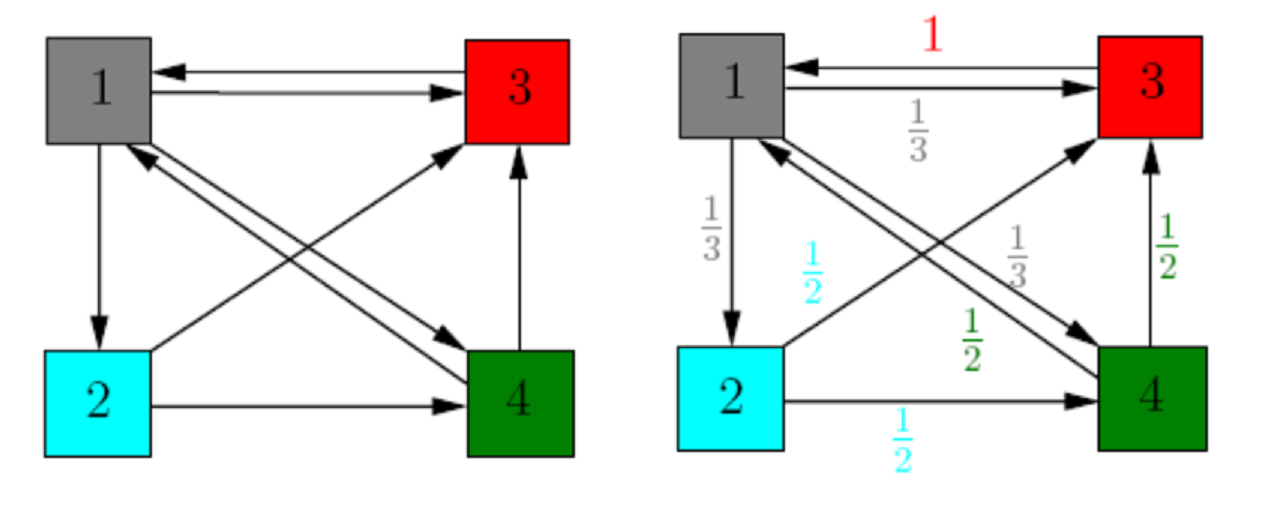

Наприклад, для графа, що його зображено вище ліворуч, орієнтовані ребра вказують на посилання сторінок (стрілка вказує на ту сторінку, на яку є посилання). На малюнку праворуч показано, яку частину свого рангу "делегують" сторінки тим  вершинам, на які вони посилаються. Наприклад, $r_1=r_3+\frac{1}{2}r_4$, оскільки $v_3$ посилається лише на $v_1$, а $v_4$ має два вихідні ребра.
Усі рівності для рангів разом можна записати у матричному вигляді. Якщо $r$ - вектор рангів, а
$T=\displaystyle \begin{pmatrix}
0 & 0 & 1 & \frac{1}{2}\\
\frac{1}{3} & 0 & 0 & 0\\
\frac{1}{3} & \frac{1}{2} & 0 & \frac{1}{2}\\
\frac{1}{3} & \frac{1}{2} & 0 & 0
\end{pmatrix}$ - матриця переходів (або ж "делегування важливостей"), то має бути виконаною рівність $$r=Tr,$$
тобто шуканий вектор рангів $r$ - це власний вектор матриці $T$, який відповідає власному значенню 1. Зазвичай, його нормують.

Чому в матриці $T$ існує власний вектор із власним значенням 1? Та ще й було б добре, щоб ранги мали невід'ємні значення. Справа в спеціальному вигляді матриці  $T$. За побудовою сума елементів кожного стовпця $T$ дорівнює 1 (такі матриці називаються стохастичними, або точніше стовпцево-стохастичними). [Теорема Фробеніуса-Перрона](https://en.wikipedia.org/wiki/Perron%E2%80%93Frobenius_theorem) (яку ми не будемо обговорювати, але інформацію про яку нескладно знайти) для достатньо широкого класу таких матриць гарантує, що 1 є їх найбільшим за модулем власним значенням і що власний вектор можна обрати з невід'ємними компонентами. Зокрема, це означає, що шукати власний вектор рангів, що відповідає власному значенню 1 можна за допомогою степеневого метода (див. попередню задачу 6.1.).

1️⃣ Для графа, що його наведено у прикладі вище, знайдіть власні значення й власні вектори матриці $T$ за допомогою вбудованих засобів. Чи є серед них власне значення 1? Чи є воно найбільшим за модулем? Яким має бути вектор рангів вершин? Знаючи, що 1  є власним значенням $T$, розрахуйте власний вектор рангів вручну, нормуйте його. Чи збігаються вектори, що їх знайшли ви та комп'ютер?

Мо ми шукаємо? 

Такий вектор $q^{*}$, що $q^{*} = q^{*} P$, де $P$ - матриця переходу тобто $P_{i} = A_{i} \cdot \frac{1}{||A_{i}||}$, де $i$ - рядок $A$, тобто матриця переходу - це матриця пронормованих рядків матриці суміжності, через що норма кодного її рядка = 1.

Звідси випливає, що  $q^{*} \in span\{ \overrightarrow{v_{1}}, \dots, \overrightarrow{v_n}\}$, де $\vec{v_{i}}$ - власний вектор $P$. Так як власні вектори хоч і не змінюють напрямку відображення(матриі переходу), але можуть стискати його чи змінювати його напрямок, тому нам потрібно знайти власний вектор від $\lambda = 1$. 

Отже, $q^{*} = \vec{v_{1}} \in \mathbb{R}^{n \times 1} : (P^{T} - I)\vec{v_{1}} = \overrightarrow{0_{\mathbb{R}^{n \times 1}}}$, де $\overrightarrow{0_{\mathbb{R}^{n \times 1}}}$ - нуль-вектор.


Логічно було б подумати, що: $(P^{T} - I)\vec{v_{1}} = \overrightarrow{0_{\mathbb{R}^{n \times 1}}} \implies \vec{v_{1}} = (P^{T} - I)^{-1} \cdot \overrightarrow{0_{\mathbb{R}^{n \times 1}}}$, але $\nexists (P^{T} - I)^{-1} \text{, так як } det(P^{T} - I) = 0$. Тому для того, щоб знайти вектор-ранг вершин мережі залишається тільки розвʼязати рівняння: $(P^{T} - I)\vec{v_{1}} = \overrightarrow{0_{\mathbb{R}^{n \times 1}}}$

In [6]:
import numpy as np
import scipy.linalg
# A - матриця суміжності мережі
A = np.array([
    [0, 1, 1, 1], # A->A, A->B, A->C, A->D
    [0, 0, 1, 1], # B->A, B->B, B->C, B->D
    [1, 0, 0, 0], # C->A, C->B, C->C, C->D
    [1, 0, 1, 0], # D->A, D->B, D->C, D->D
])

rows_deg = A.sum(axis = 1, keepdims = True)# вектор - норм кожного рядка матриці суміжності -> (4,1)
P = A/rows_deg # нормована матриця суміжності -> сума рядків = 1
print(f"{P}\n")

# rank_vector = np.linalg.solve(P.T - np.eye(len(P)), 1)# (P.T - I)rank_vector = O -> знаходимо вектор ERROR
rank_vector = scipy.linalg.null_space(P.T - np.eye(len(P))) # scipy.linalg.nullspace() - знаходить ядро матриці(v_1): Av_1 = 0. Тобто ми так само розвʼязуємо нашу систему для знаходження власного вектора
print(f"Вектор рангу вершин: {np.abs(rank_vector.flatten())}\n") #вик. можуль, бо пропорція не може бути відʼємною
# print(rank_vector.shape)

[[0.         0.33333333 0.33333333 0.33333333]
 [0.         0.         0.5        0.5       ]
 [1.         0.         0.         0.        ]
 [0.5        0.         0.5        0.        ]]

Вектор рангу вершин: [0.72101012 0.24033671 0.54075759 0.36050506]



Отже, $v_{1} = (0.72, 0.24, 0.54, 0.35)^{T}$ - "ваги"/ранг кожного вузла графа.

In [7]:
# M - матриця переходу: M_{i} = A_{i}/||A_{i}||
# M = []
# for j in range(len(A)): # going through rows
#     norma = np.sum(A[j]) #сумує рядок
#     row = A[j]/norma
#     M.append(row)#
# M = np.array(M)
# print(M)

#це саме можна реалізувати:
rows_dim = A.sum(axis = 1, keepdims = True)
M_1 = A / rows_dim

eigenvalues, eigenvectors = np.linalg.eig(M_1.T)#так як в матриця переходу це матриця рядків, а np.linalg.eig() шукає в матриці стовпців, того ми транспонуємо, щоб результат був правильним
print(f"Власні значення: \n{'\n'.join(str(ev) for ev in eigenvalues)}\n")

for i in range(len(eigenvalues)):
    if(eigenvalues[i].imag == 0):
        if( round(float(eigenvalues[i].real)) == 1):
           eigenvalues[i] = 1
print(f"Власні значення, округленні: \n{'\n'.join(str(ev) for ev in eigenvalues)}\n")# -> перше власне значення = 1

index = np.argmax(np.abs(eigenvalues))
print(f"Власні вектори: \n{eigenvectors}\n")

print(f"Найбільше власне значення по модулю: {int(eigenvalues[index].real)} -> rankvector = {eigenvectors[:, index].real}")# -> найбільним є той, що 1



Власні значення: 
(1.0000000000000016+0j)
(-0.36062333350611064+0.4109755454950541j)
(-0.36062333350611064-0.4109755454950541j)
(-0.27875333298777893+0j)

Власні значення, округленні: 
(1+0j)
(-0.36062333350611064+0.4109755454950541j)
(-0.36062333350611064-0.4109755454950541j)
(-0.27875333298777893+0j)

Власні вектори: 
[[ 0.72101012+0.j         -0.75521571+0.j         -0.75521571-0.j
   0.50648562+0.j        ]
 [ 0.24033671+0.j          0.3036721 +0.34607247j  0.3036721 -0.34607247j
  -0.60565568+0.j        ]
 [ 0.54075759+0.j          0.09315321-0.2746779j   0.09315321+0.2746779j
  -0.38153917+0.j        ]
 [ 0.36050506+0.j          0.3583904 -0.07139457j  0.3583904 +0.07139457j
   0.48070923+0.j        ]]

Найбільше власне значення по модулю: 1 -> rankvector = [0.72101012 0.24033671 0.54075759 0.36050506]


У моделі мережі для обчислення рангу сторінок, що наведено вище, є певний недолік. Адже граф інтернету є величезним і може бути незв'язним. Наприклад, з точки зору моделі випадкового блукача це означає, що цей блукач може пересуватися лише в межах однієї компоненти зв'язності й ніколи не потрапить до інших. З точки зору лінійної алгебри це означає, що матриця переходів матиме кілька лінійно незалежних власних векторів, що відповідають значенню 1 і ми не зможемо обрати з них єдиний вектор рангів.  Для того щоб виправити ситуацію, модель (і відповідну матрицю) дещо змінюють.
А саме вважають, що на кожному кроці випадковий блукач обирає або переходити йому з поточної сторінки на якусь пов'язану за посиланням, або ж взагалі перестрибнути на якусь довільну сторінку в мережі (яка не обов'язково пов'язана з поточною). Ймовірність, з якою блукач обирає перший спосіб дій  позначають $d$ (damping number), відповідно, ймовірність стрибку на випадкову сторінку дорівнює $1-d$. Це означає, що матриця переходів $T$ перетворюється на нову матрицю $$G= d\cdot T+ (1-d)H_n,$$ де $n$ -- загальна кількість вершин графа, а $H_n$ -- матриця, усі елементи якої дорівнюють $1/n$ (адже з-поміж усіх сторінок випадковий блукач обирає одну з ймовірністю $1/n$). Матрицю $G$ зазвичай називають Google-матрицею. Число $d$ є комерційною таємницею корпорації  Google, але вважається, що воно дорівнює $d=0.85$, також часто обирають $d$ між 0.85 і 0.99.

2️⃣ Зверніть увагу, що матриця $H_n$ також є стовпцево-стохастичною. Перевірте, що й матриця $G$ є стовпцево-стохастичною і що всі її елементи є додатними. До речі, для такого вигляду матриці теорема Фробеніуса-Перрона завжди гарантує, що 1 є найбільшим за модулем власним значенням кратності 1, і що відповідний власний вектор можна обрати з додатними компонентами.

$H_{n} =  \frac{1}{n} \cdot E = 
 \begin{pmatrix}
 \frac{1}{n} &  \frac{1}{n} & \dots &  \frac{1}{n} \\ 
 \frac{1}{n} &  \frac{1}{n} & \dots &  \frac{1}{n} \\ 
 \vdots &  \vdots & \ddots & \vdots \\ 
 \frac{1}{n} &   \frac{1}{n} & \dots &  \frac{1}{n}
 \end{pmatrix} \text{ - стовпцево-стохастична, бо } \forall i : \sum_{j = 1}^{n}A_{ij} = 1 \text{ i } \forall A_{ij} \geq 0 \text{, де } i \text{ - стовпець} \stackrel{?}{\implies} G = d \cdot T + (1 - d)H_{n} \text{ - стовпцево-стохастична}$

 Так як $\forall i, j \in \mathbb{R}_{n}\quad H_{i} = 1, \text{ де } i \text{ - стовпець} \implies (1 - d) \cdot H_{i} = 1- d$
>Наприклад: $H_{2} = \begin{pmatrix} \frac{1}{2} & \frac{1}{2} \\ \frac{1}{2} & \frac{1}{2} \end{pmatrix}, d = 0.85 \implies (1 - d)H_{2} = 0.15 \cdot H_{2} = \frac{3}{20} \cdot \begin{pmatrix} \frac{1}{2} & \frac{1}{2} \\ \frac{1}{2} & \frac{1}{2} \end{pmatrix} = \begin{pmatrix} \frac{3}{40} & \frac{3}{40} \\ \frac{3}{40} & \frac{3}{40} \end{pmatrix}$. Тоді $||H_{1,2}|| = \frac{3}{40} + \frac{3}{40} = \frac{6}{40} = 0.15$

Те саме застосовується для $d \cdot T: \forall ||T_{i}|| = d$
> Наприклад: $T  = \begin{pmatrix} 1 & 0 \\ 0 & 1\end{pmatrix} \cdot \frac{1}{||T_{i}||} \text{, де і - рядок} = \begin{pmatrix} 1 & 0 \\ 0 & 1\end{pmatrix} \implies d \cdot T = \frac{17}{20} \cdot \begin{pmatrix} 1 & 0 \\ 0 & 1\end{pmatrix}  = \begin{pmatrix} \frac{17}{20} & 0 \\ 0 & \frac{17}{20} \end{pmatrix}$. Тоді $||(d\cdot T)_{1, 2}|| = \frac{17}{20} = 0.85 = d$.

звідси випливає, що $||G_{i}|| = ||( d\cdot T)_{i}|| + ||((1 - d) \cdot H_{n})_{i}|| = 0.85 + 0.15 = 1$. Отже, $G$ - стовпцево-стохастична матриця.

3️⃣ Напишіть функцію, що отримує на вхід орієнтований граф (networkx.Digraph),  й обчислює його Google-матрицю $G =d\cdot T+ (1-d)H_n$. Число $d$ також має бути параметром. Застосуйте функцію до графа з прикладу з $d=0.85$. Обчисліть ранги вершин графа, згадавши, що вони мають утворювати власний вектор, що відповідає власному значенню 1 матриці $G$. Не забувайте, що компонентами мають бути додатні числа, а сам вектор -- нормованим. Для знаходження власного вектора ви можете використовувати вбудовані засоби або ж реалізувати степеневий метод з попередньої задачі 6.1.

Google matrix: 

The page range of a graph: 
[[0.16327621]
 [0.0300367 ]
 [0.3898005 ]
 [0.22253591]
 [0.19731363]
 [0.14855115]
 [0.19421826]
 [0.27800578]
 [0.28720102]
 [0.42676951]
 [0.17054531]
 [0.11304737]
 [0.06160381]
 [0.09739944]
 [0.11668773]
 [0.26681488]
 [0.13412794]
 [0.21478726]
 [0.19531923]
 [0.29685104]]



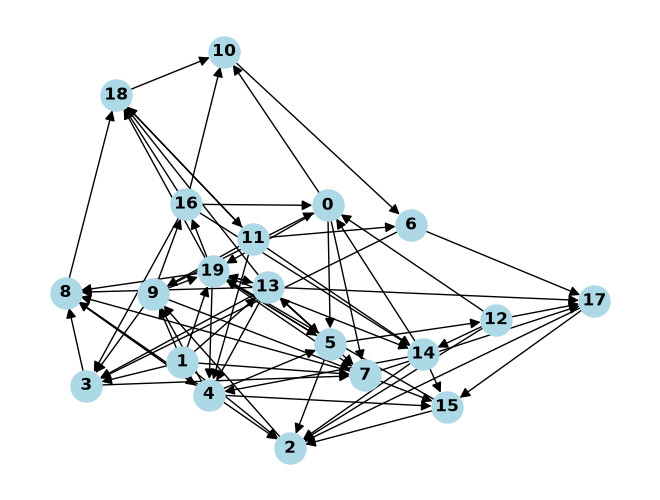

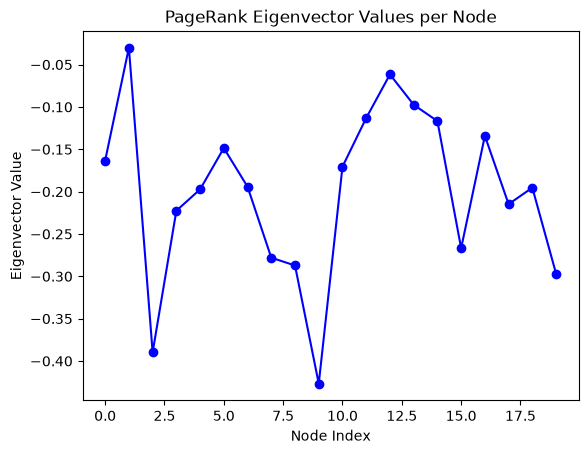

In [85]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg

def Google_matrix(graph:nx.DiGraph, d = 0.85 ):
    n = graph.number_of_nodes() #calcualting how much nodes there are
    if n == 0:
        InterruptedError

    A = nx.to_numpy_array(graph).T #converting graph into a numpy array, then transpose it(since the adgecency matrix represents grapg in rows, rather thn in columns)
    norma_vector = A.sum(axis = 0, keepdims = True)
    norma_vector[norma_vector == 0] = 1
    T = A / norma_vector #creating a transotion matrix

    H = np.ones((len(T), len(T))) / len(T) # a matrix of ones
    return d * T + (1 - d) * H



def create_graph():
   nodes_list = list(map(float, input("Pleaase enter the graph's nodes: ").split()))
   nx_graph = nx.DiGraph() # initializing a graph
   nx_graph.add_nodes_from(nodes_list) #adding graph's nodes

   print("Please enter the graph's links, using such an input format: 'from to'. \n If you finish, please enter 'finish'.")
   while(True):
    curr_edge = input("Add an edge: ")
    if(curr_edge.lower() == 'finish'):
       break
    try: 
       u, v = map(int, curr_edge.split())
       nx_graph.add_edge(u, v)
    except ValueError:
       print("Invalid format! Please double-check what you've entered.")
   return nx_graph

# graph = create_graph()#creating a graph
graph = nx.gnp_random_graph(20, 0.175, directed=True) #. where the first parameter is the number of nodes, the second: the probability of edges()that there will be an edge
G = Google_matrix(graph)

print("Google matrix: \n")
nx.draw(
   graph,
   with_labels= True,
   node_color="lightblue",
   node_size= 500,
   arrowsize= 15,
   font_weight= "bold"
)

# 1. Pass only the matrix to null_space (dropped the np.zeros)
rank = scipy.linalg.null_space(G - np.eye(len(G)))
print(f"The page range of a graph: \n{abs(rank)}\n")

# 2. Extract the first eigenvector column and flatten it to 1D for clean plotting
if rank.size > 0:
    vector_to_plot = rank[:, 0]
    
    plt.figure()
    plt.plot(vector_to_plot, marker='o', linestyle='-', color='b')
    plt.title("PageRank Eigenvector Values per Node")
    plt.xlabel("Node Index")
    plt.ylabel("Eigenvector Value")
    plt.show()
else:
    print("No null space found.")

4️ Порівняйте ваші розрахунки з тими, що дають вбудовані засоби ([див.](https://networkx.org/documentation/stable/reference/algorithms/link_analysis.html) функціі google_matrix, pagerank у пакеті  networkx ) на тому ж графі з прикладу. Чим відрізняються результати? Зробіть висновки: яка з вершин графа має найбільший ранг, найменший. Чи можете ви пояснити, чому?

In [87]:
import networkx as nx
import numpy as np

G_1 = nx.google_matrix(graph, weight = None)
eigenvalues, eigenvectors = np.linalg.eig(G_1)
for i in range(len(eigenvalues)):
    if(np.isclose(eigenvalues[i].real, 1)):
        index = i
print(f"The page rank of a graph is: \n {np.abs(eigenvectors[index])} \n")
print(f"Найбільший ранг: {np.max(np.abs(eigenvectors[:, index]))} у {np.argmax(np.max(np.abs(eigenvectors[:, index])))}-го рядка вектора-рангу")


The page rank of a graph is: 
 [0.2236068  0.09525311 0.09525311 0.17987118 0.17987118 0.13285117
 0.29377264 0.29377264 0.18116777 0.36921943 0.36921943 0.31072436
 0.31072436 0.27249189 0.27249189 0.17279544 0.17279544 0.07898597
 0.07898597 0.00755258] 

Найбільший ранг: 0.22360679774997935 у 0-го рядка вектора-рангу


✔️ *Ваші міркування запишіть тут.*

<font color="red"> *Коментар викладача:* <font>